In [1]:
import sys
from pathlib import Path
import importlib

ROOT = Path.cwd()
for candidate in [ROOT, *ROOT.parents]:
    if (candidate / "src").is_dir() and (candidate / "project.ipynb").is_file():
        ROOT = candidate
        break
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from pyspark.sql import SparkSession
from src.dataOI import DataOI

SEED = 42
# True: rebuild the encoded split from the raw CSV; False: load its local cache.
# The flag controls input preparation, not model training.
REBUILD = True

BASELINE = True

# `spark.driver.memory` is read only when the JVM starts. Restart the kernel after changing it.
spark = SparkSession.builder \
                            .master("local[*]")\
                            .appName("DrugReviewClassification")\
                            .config("spark.driver.memory","6g")\
                            .getOrCreate()
spark_context = spark.sparkContext
spark_context.setLogLevel("ERROR")
data_oi = DataOI()


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/06 01:17:25 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


In [2]:
df_raw = data_oi.load_raw_data()
df_raw.show(truncate= 80)
print("rows:", df_raw.count())

+--------+----------------------------------+----------------------------+--------------------------------------------------------------------------------+------+----------+-----------+
|uniqueID|                          drugName|                   condition|                                                                          review|rating|      date|usefulCount|
+--------+----------------------------------+----------------------------+--------------------------------------------------------------------------------+------+----------+-----------+
|  206461|                         Valsartan|Left Ventricular Dysfunction| "It has no side effect, I take it in combination of Bystolic 5 Mg and Fish Oil"|     9|2012-05-20|         27|
|   95260|                        Guanfacine|                        ADHD|"My son is halfway through his fourth week of Intuniv. We became concerned wh...|     8|2010-04-27|        192|
|   92703|                            Lybrel|               Birth Cont

### Exploratory Data Analysis (EDA)

Begin by trying to comprehend what your dataset conveys.

- What type of data are you currently exploring?
- What is the granularity of the data?
- What does the distribution of the data look like? Are there any outliers? Are there any missing or invalid entries?
- Is there any correlation between the variables you are interested in exploring?
- How would you cleanly and accurately visualize the relationship among variables?

In [3]:
from src.eda import EDA
if REBUILD:
    eda_raw = EDA(df_raw)
    eda_raw.dataframe_overview()

DataFrame overview
+--------+------------------------+----------------------------+--------------------------------------------------------------------------------+------+----------+-----------+
|uniqueID|                drugName|                   condition|                                                                          review|rating|      date|usefulCount|
+--------+------------------------+----------------------------+--------------------------------------------------------------------------------+------+----------+-----------+
|  206461|               Valsartan|Left Ventricular Dysfunction| "It has no side effect, I take it in combination of Bystolic 5 Mg and Fish Oil"|     9|2012-05-20|         27|
|   95260|              Guanfacine|                        ADHD|"My son is halfway through his fourth week of Intuniv. We became concerned wh...|     8|2010-04-27|        192|
|   92703|                  Lybrel|               Birth Control|"I used to take another oral contrace

#### Fields

Each row is one comment on a drug, with the condition and a satisfaction score. The fields mix free text, categories, integers, and a date.

| Field | Type | Content |
|---|---|---|
| `uniqueID` | integer | Review identifier. There is no patient identifier. |
| `drugName` | string | Drug name as written. |
| `condition` | string | Condition or indication. |
| `review` | string | Comment text. Some values contain HTML entities such as `&#039;` and surrounding quotation marks. |
| `rating` | integer | Satisfaction score from 1 to 10. |
| `date` | date | Publication date. |
| `usefulCount` | integer | Helpful votes accumulated after publication. |


In [4]:
if REBUILD: eda_raw.granularity()

DataFrame granularity
Total row count: 161297
`drugName`:
+-------------------------------+
|                       drugName|
+-------------------------------+
|                         Dulera|
|                         Prozac|
|                          Arava|
|                         Maxalt|
|                     Tazarotene|
|                      Primidone|
|Acetaminophen / diphenhydramine|
|                       Treximet|
|                         Avapro|
|                        Prograf|
|                      Auranofin|
|               Spiriva Respimat|
|              Parafon Forte DSC|
|                       Dupixent|
|                      Nebivolol|
|                         Nexium|
|                         Ceftin|
|                        Enjuvia|
|                    Benicar HCT|
|                    Penciclovir|
+-------------------------------+
only showing top 20 rows
`drugName` count: 3436
`condition`:


+-------------------------------------------+
|                                  condition|
+-------------------------------------------+
|    High Cholesterol, Familial Heterozygous|
|                         Pulmonary Embolism|
|                                 Nightmares|
|                        Chlamydia Infection|
|                         Hypoparathyroidism|
|             CNS Magnetic Resonance Imaging|
|                               Body Imaging|
|                         Rabies Prophylaxis|
|                        Atrial Fibrillation|
|       Endometrial Hyperplasia, Prophylaxis|
|            Prevention of Bladder infection|
|14</span> users found this comment helpful.|
|                              Panic Disorde|
|                               Stomach Ulce|
|                           Behcet's Disease|
|    Organ Transplant, Rejection Prophylaxis|
|                               Anal Itching|
|                 Oral and Dental Conditions|
|                           Gender

`review` is not unique: 48635 groups contain duplicate `review` values
+--------------------------------------------------------------------------------+---+--------+
|                                                                          review|  n|rating_n|
+--------------------------------------------------------------------------------+---+--------+
|"This Medication is Awseome! I have lost 25 pounds in 4 months.  My A1C went ...|  2|       1|
|"I was born into the middle of WWII in England and have Post Traumatic Stress...|  2|       1|
|"This was for a bowel prep. Liquids 2 days before and it still didn&#039;t wo...|  2|       1|
|"This is my first week taking contrave, and so far  I have had no side effect...|  2|       1|
|"My 8 year old daughter was prescribed this medication yesterday by our PCP. ...|  2|       1|
+--------------------------------------------------------------------------------+---+--------+
only showing top 5 rows
But only 72 groups of `review` have diffe

#### Granularity

The file has **161,297** reviews. `uniqueID` is unique, and the file has no patient identifier, so this is a review count.

- **3,436** distinct `drugName` strings. One comment can appear under more than one name, such as Sertraline and Zoloft.
- **885** distinct `condition` values, including null and text that is not a condition name.
- **48,635** groups share identical `review` text. **72** of those groups contain more than one `rating`.


Data Distribution
`rating` is in the range [1, 10]
`rating` record count:
+------+-----+
|rating|count|
+------+-----+
|     1|21619|
|     2| 6931|
|     3| 6513|
|     4| 5012|
|     5| 8013|
|     6| 6343|
|     7| 9456|
|     8|18890|
|     9|27531|
|    10|50989|
+------+-----+

+------------------+-----------------+-------------------+
|          variance|           stddev|           skewness|
+------------------+-----------------+-------------------+
|10.708138452208162|3.272329209020413|-0.7986194576447084|
+------------------+-----------------+-------------------+

`usefulCount`:
+-------+-----------+
|summary|usefulCount|
+-------+-----------+
|    min|          0|
|    25%|          6|
|    50%|         16|
|    75%|         36|
|    max|       1291|
+-------+-----------+

The highest `usefulCount` record:
+--------+----------+----------+--------------------------------------------------------------------------------+------+----------+-----------+
|uniqueID|  drugName| condi

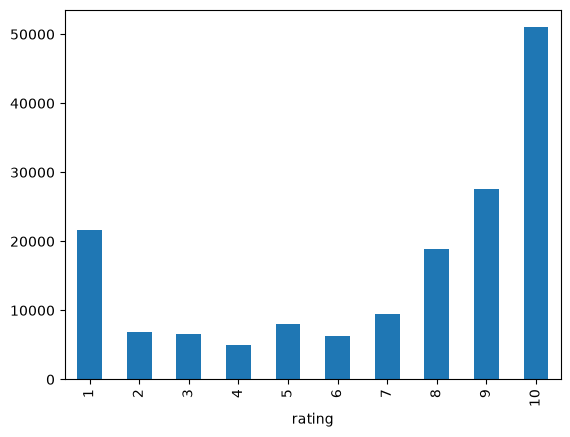

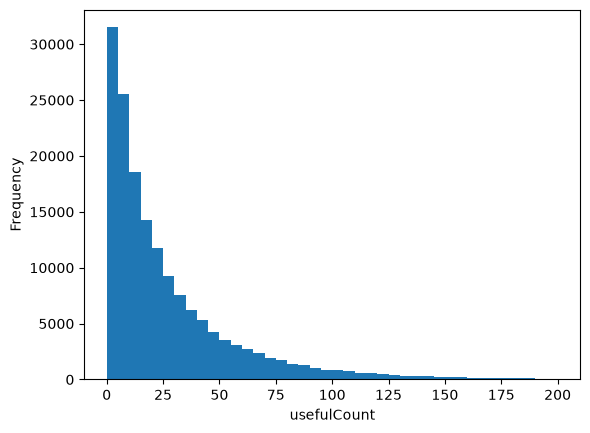

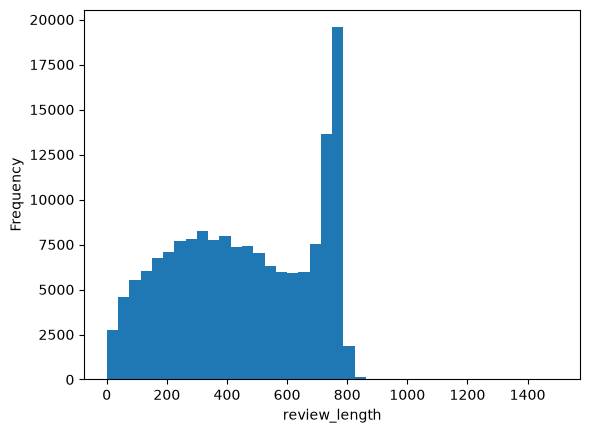

In [5]:
if REBUILD: eda_raw.distribution_inspect()

#### Distributions and invalid values

`rating` stays inside 1–10. The scores pile up at the ends: **50,989** reviews (31.6%) are 10 and **21,619** (13.4%) are 1, while 2–7 are smaller. The standard deviation is 3.27 and the skewness is −0.80.

`usefulCount` has a long right tail (skewness 4.67). The median is 16, the third quartile is 36, and the maximum is 1,291. That maximum is one comment stored twice, under Sertraline and Zoloft.

Review length has a median of 455 characters and a maximum of 10,745. Six comments are three characters long. Some `condition` labels are truncated, including `Testicular Cance` and `min)`.

| Issue | Rows |
|---|---|
| Null `condition` | 899 (0.56%) |
| Helpful-vote text stored in `condition` | 900 (0.56%) |
| Nulls in the other six fields | 0 |
| Whitespace-only values | 0 |
| `rating` outside the integers 1–10 | 0 |
| Negative or non-numeric `usefulCount` | 0 |
| Dates that fail `d-MMM-yy`, or fall after 2026-11-02 | 0 |

The 900 `condition` values are page fragments such as `2</span> users found this comment helpful.`, separate from the 899 nulls. Comment text also contains HTML entities such as `&#039;`, and some condition names are cut off, such as `Panic Disorde` and `Stomach Ulce`.


In [6]:
if REBUILD: eda_raw.correlation()

Data Field Correlation
+------------------+--------------------+-------------------+
|rating_usefulCount|         rating_date|   usefulCount_date|
+------------------+--------------------+-------------------+
|0.2341853750636649|-0.19623579544730904|-0.2690699925232411|
+------------------+--------------------+-------------------+



#### Correlations

Pearson correlation uses `rating`, `usefulCount`, and `date` as days since 1970-01-01. A larger date value is a later review.

| Pair | r | Reading |
|---|---:|---|
| Rating, helpful votes | 0.234 | Higher ratings tend to receive somewhat more votes. |
| Rating, date | −0.196 | Later reviews have slightly lower ratings. |
| Helpful votes, date | −0.269 | Earlier reviews have more votes, consistent with a longer time to collect them. |

All three absolute values are below 0.3, so the linear associations are weak. `rating` is an ordinal score, and `usefulCount` has a long right tail. Drug and condition names stay categorical and are left out of this calculation.


Data Field Correlation Heatmap


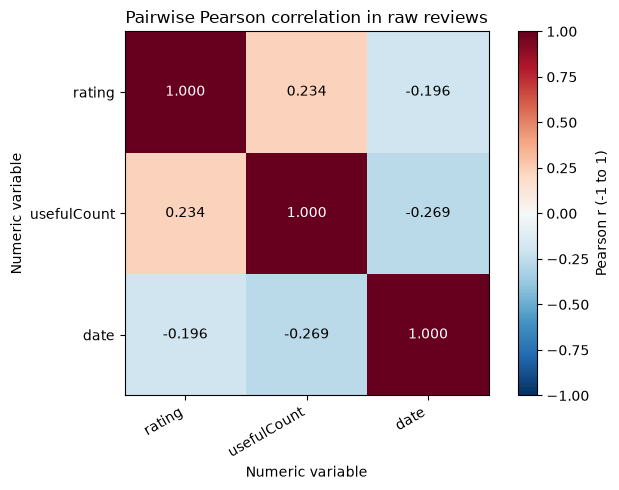

In [7]:
if REBUILD: eda_raw.correlation_heatmap()

### Data Cleaning
A crucial step in the data preprocessing pipeline, aimed at improving the quality and accuracy of the dataset before analysis.
- Identifying Missing Values
- Handling Outliers
- Correcting Invalid Entries
- Removing Duplicates
- Standardizing Data: Ensure consistency in data representation.
- Transforming Variables: Apply necessary transformations to variables to enhance their interpretability or suitability for analysis.

Before data cleaning:
+--------+----------------------------------+----------------------------+--------------------------------------------------------------------------------+------+----------+-----------+
|uniqueID|                          drugName|                   condition|                                                                          review|rating|      date|usefulCount|
+--------+----------------------------------+----------------------------+--------------------------------------------------------------------------------+------+----------+-----------+
|  206461|                         Valsartan|Left Ventricular Dysfunction| "It has no side effect, I take it in combination of Bystolic 5 Mg and Fish Oil"|     9|2012-05-20|         27|
|   95260|                        Guanfacine|                        ADHD|"My son is halfway through his fourth week of Intuniv. We became concerned wh...|     8|2010-04-27|        192|
|   92703|                            Lybrel|   

After replacement: 0 `condition` values still match configured repairs, 0 `review` values contain HTML entities


After keeping the row with the highest `usefulCount` for each `review`
Row count: 159498 -> 111167, removed 48331 rows
Added `usefulCount_log` = log(1 + `usefulCount`)


+---------------+------------------+------------------+--------------------+
|         column|          variance|            stddev|            skewness|
+---------------+------------------+------------------+--------------------+
|    usefulCount| 1281.077141590041| 35.79213798573705|  4.4880402100310315|
|usefulCount_log|1.4185266277513164|1.1910191550732157|-0.29665492455691056|
+---------------+------------------+------------------+--------------------+

Added `days` = days since 1970-01-01 from `date`
Set `rating_p1` = `rating` - 1


After data cleaning:
+--------+------------------------------------------------------+-------------------+--------------------------------------------------------------------------------+------+----------+-----------+------------------+-----+---------+
|uniqueID|                                              drugName|          condition|                                                                          review|rating|      date|usefulCount|   usefulCount_log| days|rating_p1|
+--------+------------------------------------------------------+-------------------+--------------------------------------------------------------------------------+------+----------+-----------+------------------+-----+---------+
|  128876|                                           Phentermine|        Weight Loss|4 and half weeks in, starting weight 14.3 now weighing 13.5 nearly lost a sto...|     9|2014-07-06|          8|2.1972245773362196|16257|        8|
|  131325|                                         

+---------------------------------+
|                         drugName|
+---------------------------------+
|                           Maxalt|
|                           Avapro|
|  Acetaminophen / diphenhydramine|
|                           Prozac|
|                         Treximet|
|                        Nebivolol|
|                           Nexium|
|                       Gabapentin|
|                          Privine|
|                 Dextromethorphan|
|                        Adapalene|
|                      Dulaglutide|
|                   Levocetirizine|
|                           Zoloft|
|Ethinyl estradiol / norethindrone|
|                           Copper|
|                       Vilazodone|
|                        Tadalafil|
|                Divalproex sodium|
|                           Avelox|
+---------------------------------+
only showing top 20 rows
`drugName` count: 

2963
`condition`:


+-------------------------------------------+
|                                  condition|
+-------------------------------------------+
|    High Cholesterol, Familial Heterozygous|
|    Organ Transplant, Rejection Prophylaxis|
|                          Cluster Headaches|
|                             Panic Disorder|
|                  Abnormal Uterine Bleeding|
|                       Rheumatoid Arthritis|
|                                   Headache|
|                                     Angina|
|                                Prostatitis|
|            Premenstrual Dysphoric Disorder|
|                              HIV Infection|
|              Skin or Soft Tissue Infection|
|                                 Anesthesia|
|         Nausea/Vomiting, Radiation Induced|
|                          Opiate Withdrawal|
|                                   Anorexia|
|                                   Seizures|
|                      Human Papilloma Virus|
|                         Anxiety 

805


`uniqueID` is unique


`review` values are unique
`uniqueID` has 0 null records
`drugName` has 0 null records
`condition` has 0 null records
`review` has 0 null records
`rating` has 0 null records
`date` has 0 null records
`usefulCount` has 0 null records
`usefulCount_log` has 0 null records
`days` has 0 null records
`rating_p1` has 0 null records
Data Distribution
`rating` is in the range [1, 10]
`rating` record count:
+------+-----+
|rating|count|
+------+-----+
|     1|14955|
|     2| 4742|
|     3| 4424|
|     4| 3412|
|     5| 5514|
|     6| 4351|
|     7| 6550|
|     8|13074|
|     9|18938|
|    10|35207|
+------+-----+

+------------------+------------------+-------------------+
|          variance|            stddev|           skewness|
+------------------+------------------+-------------------+
|10.709368948658776|3.2725172190011125|-0.8023165592189497|
+------------------+------------------+-------------------+

`usefulCount`:
+-------+-----------+
|summary|usefulCount|
+-------+-----------+
|    m

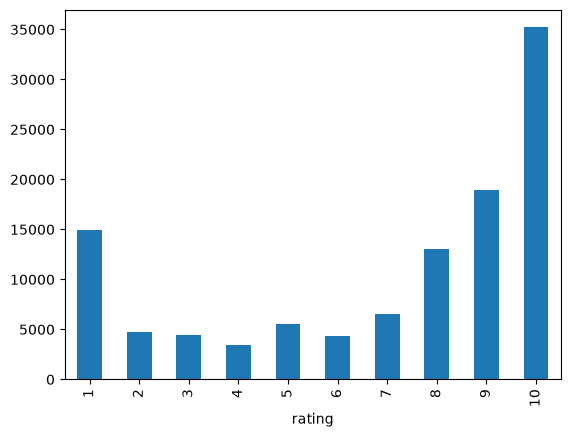

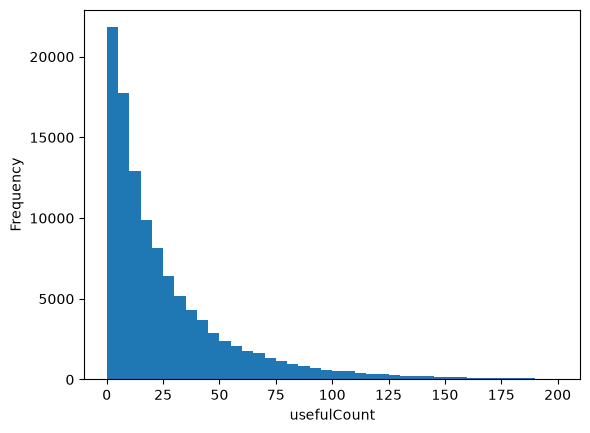

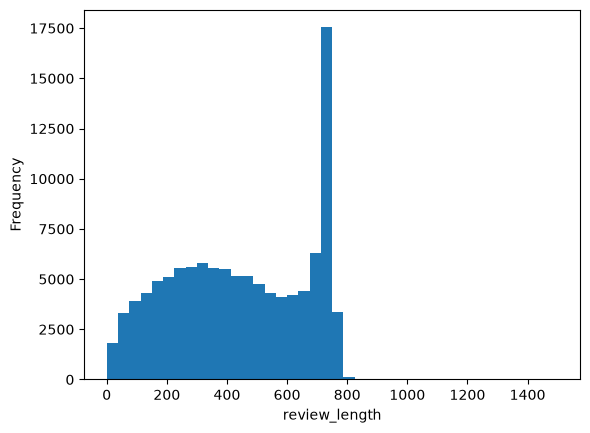

In [8]:
from src.cleaning import data_cleaning

if REBUILD:
    print("Before data cleaning:")
    df_raw.show(10,truncate=80)
    df_cleaned = data_cleaning(df_raw)
    df_cleaned.cache().count()
    print("After data cleaning:")
    df_cleaned.show(10,truncate=80)
    print("Cleaned data overview:")
    eda_cleaned = EDA(df_cleaned)
    eda_cleaned.dataframe_overview()
    eda_cleaned.granularity()
    eda_cleaned.distribution_inspect()


In [9]:
from src.text_features import text_feature_engineering

if REBUILD:
    print("Before text feature engineering:")
    df_cleaned.show(10,truncate = 80)
    df_engineered = text_feature_engineering(df_cleaned,True)
    df_engineered.cache().count()
    print("After text feature engineering:")
    df_engineered.show(10,truncate = 80)


Before text feature engineering:
+--------+------------------------------------------------------+-------------------+--------------------------------------------------------------------------------+------+----------+-----------+------------------+-----+---------+
|uniqueID|                                              drugName|          condition|                                                                          review|rating|      date|usefulCount|   usefulCount_log| days|rating_p1|
+--------+------------------------------------------------------+-------------------+--------------------------------------------------------------------------------+------+----------+-----------+------------------+-----+---------+
|  128876|                                           Phentermine|        Weight Loss|4 and half weeks in, starting weight 14.3 now weighing 13.5 nearly lost a sto...|     9|2014-07-06|          8|2.1972245773362196|16257|        8|
|  131325|                             

Before character repair: 741 `review` values require character or whitespace normalization


After character repair: 0 `review` values would change on a second pass (idempotence check)


Contraction repair and expansion: 63215 `review` values changed


After text feature engineering:
+--------+------------------------------------------------------+-------------------+--------------------------------------------------------------------------------+-----+------------------+------+---------+--------------------------------------------------------------------------------+--------------------------------------------------------------------------------+
|uniqueID|                                              drugName|          condition|                                                                  words_featured| days|   usefulCount_log|rating|rating_p1|                                                                          review|                                                                           words|
+--------+------------------------------------------------------+-------------------+--------------------------------------------------------------------------------+-----+------------------+------+---------+------------------

In [10]:
from src.encoder import encoder
from src.split import split_and_weight


if REBUILD:
    df_train, df_valid, df_test = split_and_weight(df_engineered, SEED)
    df_train, df_valid, df_test = encoder(df_train, df_valid, df_test)
    data_oi.save_split_data(df_train, df_valid, df_test)
else:
    df_train, df_valid, df_test = data_oi.load_split_data()

In [11]:
from src.embeddings import EmbeddingModel
from src.text_features import baseline_text_feature_engineering
# Embedding Baseline Model (TFIDF without text feature engineering)

if BASELINE:
    if not REBUILD: df_cleaned = data_cleaning(df_raw)
    
    df_baseline_engineered = baseline_text_feature_engineering(df_cleaned)
    df_baseline_engineered.cache().count()
    df_baseline_train, df_baseline_valid, df_baseline_test = split_and_weight(df_baseline_engineered,SEED)
    df_baseline_train, df_baseline_valid, df_baseline_test = encoder(df_baseline_train, df_baseline_valid, df_baseline_test)

    
    embedding_baseline_model = EmbeddingModel(df_baseline_train, df_baseline_valid, df_baseline_test)
    baseline_name = "baseline"
    print("Embedding Baseline Model `baseline` Training")
    embedding_baseline_model.tfidf_train(baseline_name)
    print("Embedding Baseline Model `baseline` Running")
    train_embedding_baseline, valid_embedding_baseline, test_embedding_baseline = embedding_baseline_model.tfidf_predict(baseline_name)

Embedding Baseline Model `baseline` Training


Embedding Baseline Model `baseline` Running


In [12]:
from src.embeddings import EmbeddingModel

# Fit registered embeddings before prediction; downstream models read `embedding`.
embedding_model = EmbeddingModel(df_train, df_valid, df_test)

for name, train_function in EmbeddingModel.train_registry.items():
    print(f"Embedding Model `{name}` Training")
    train_function(embedding_model)

Embedding Model `tfidf` Training


In [13]:
train_embedding_dict = {}
valid_embedding_dict = {}
test_embedding_dict = {}

for name, predict_function in EmbeddingModel.predict_registry.items():
    print(f"Embedding Model `{name}` Running")
    train_embedding_dict[name], valid_embedding_dict[name], test_embedding_dict[name] = predict_function(embedding_model)
    data_oi.save_embedding_data(name,train_embedding_dict[name], valid_embedding_dict[name], test_embedding_dict[name])

Embedding Model `tfidf` Running


In [14]:
from src.analytics import AnalyticsModel

# Analytics Baseline Model (Logistic Regression Model without weight col)
if BASELINE:
    analytics_baseline_model = AnalyticsModel(baseline_name, train_embedding_baseline, valid_embedding_baseline, test_embedding_baseline)
    print("Embedding Baseline Model `TFIDF` Analytics Baseline Model `lr`")
    train_analytics_baseline, valid_analytics_baseline, test_analytics_baseline = analytics_baseline_model.baseline()
    data_oi.save_prediction_data(
        f"lr__{baseline_name}",
        train_analytics_baseline,
        valid_analytics_baseline,
        test_analytics_baseline,
    )

Embedding Baseline Model `TFIDF` Analytics Baseline Model `lr`


In [15]:
# Analytics Model Prediction
from src.analytics import AnalyticsModel

analytics_models = {}
train_pred_dict = {}
valid_pred_dict = {}
test_pred_dict = {}

for embedding_name in train_embedding_dict.keys():
    analytics_models[embedding_name] = AnalyticsModel(
        embedding_name,
        train_embedding_dict[embedding_name],
        valid_embedding_dict[embedding_name],
        test_embedding_dict[embedding_name]
    )
    for name, function in AnalyticsModel.registry.items():
        print(f"Embedding Model `{embedding_name}` Analytics Model `{name}`")
        # Format: `{analytics}__{embedding}`. Either name may contain a single underscore.
        model_name = f"{name}__{embedding_name}"
        train_pred_dict[model_name], valid_pred_dict[model_name], test_pred_dict[model_name] = function(
            analytics_models[embedding_name]
        )
        data_oi.save_prediction_data(
            model_name,
            train_pred_dict[model_name],
            valid_pred_dict[model_name],
            test_pred_dict[model_name]
        )


Embedding Model `tfidf` Analytics Model `lr_improved`


In [16]:
from src.evaluation import Scorer

train_pred_dict, valid_pred_dict, test_pred_dict = data_oi.load_prediction_data()

scorer_train = Scorer(train_pred_dict)
scorer_valid = Scorer(valid_pred_dict)
scorer_test = Scorer(test_pred_dict)

print("Training Data:")
scorer_train.show_metrics(truncate = 80)

print("Validation Data:")
scorer_valid.show_metrics(truncate = 80)


Training Data:
+---------------+--------------+------------------+------------------+------------------+------------------+--------------------+-------------------+
|Embedding_Model|Analytic_Model|          accuracy|weighted_precision|   weighted_recall|       weighted_f1|                 mae|               rmse|
+---------------+--------------+------------------+------------------+------------------+------------------+--------------------+-------------------+
|          tfidf|   lr_improved| 0.739318766066838|0.7488721548302683|0.7393187660668379|0.7371066059390808|  0.7359768637532134| 1.8557179058292845|
|       baseline|            lr|0.9967994858611825|0.9968003007960278|0.9967994858611824|0.9967988951586557|0.005809768637532134|0.14421135588813772|
+---------------+--------------+------------------+------------------+------------------+------------------+--------------------+-------------------+

Validation Data:
+---------------+--------------+-------------------+---------------

In [17]:
print("Testing Data:")
scorer_test.show_metrics(truncate = 80)

Testing Data:
+---------------+--------------+-------------------+-------------------+-------------------+------------------+------------------+------------------+
|Embedding_Model|Analytic_Model|           accuracy| weighted_precision|    weighted_recall|       weighted_f1|               mae|              rmse|
+---------------+--------------+-------------------+-------------------+-------------------+------------------+------------------+------------------+
|          tfidf|   lr_improved|0.35027002700270027|0.38215233600872894| 0.3502700270027002|0.3637110862514363|1.6736273627362737|2.6444412088247855|
|       baseline|            lr|0.27997299729972996|0.29569565367527556|0.27997299729972996|0.2870951917844777| 2.184968496849685| 3.260529574365264|
+---------------+--------------+-------------------+-------------------+-------------------+------------------+------------------+------------------+

